# Spectral Embedding, Clustering & Peak Calling

In [1]:
import gatac as ga
import scanpy as sc
import rapids_singlecell as rsc
import anndata as ad
import time

sc.set_figure_params(dpi=100, frameon=False)

adata = ad.read_h5ad("data/pbmc_tile.h5ad")
print(adata)

AnnData object with n_obs × n_vars = 5001 × 6062095
    obs: 'barcode', 'n_unique', 'tsse_score', 'duplicate_fraction', 'mito_fraction'
    var: 'chrom', 'start', 'end', 'selected', 'accessibility_count'
    layers: None (.X)


## 1. Spectral embedding

Compute a spectral decomposition of the TF-IDF-normalised cell × tile matrix.
The resulting components are stored in `adata.obsm["X_spectral"]`.

In [2]:
t0 = time.perf_counter()
ga.dr.spectral(adata, n_comps=30)
print(f"Spectral embedding in {time.perf_counter() - t0:.1f}s")
print(f"Embedding shape: {adata.obsm['X_spectral'].shape}")

13:56:26 - gatac.dr.spectral - INFO - Running GPU-accelerated spectral embedding ...


13:56:28 - gatac.dr.spectral - INFO - IDF weights computed.


13:56:28 - gatac.dr.spectral - INFO - Row normalization done.


13:56:28 - gatac.dr.spectral - INFO - Eigen-decomposition done.


13:56:28 - gatac.dr.spectral - INFO - Spectral embedding complete: 30 components (top eigenvalue = 1.0000).


Spectral embedding in 2.3s
Embedding shape: (5001, 30)


## 2. UMAP & Leiden clustering

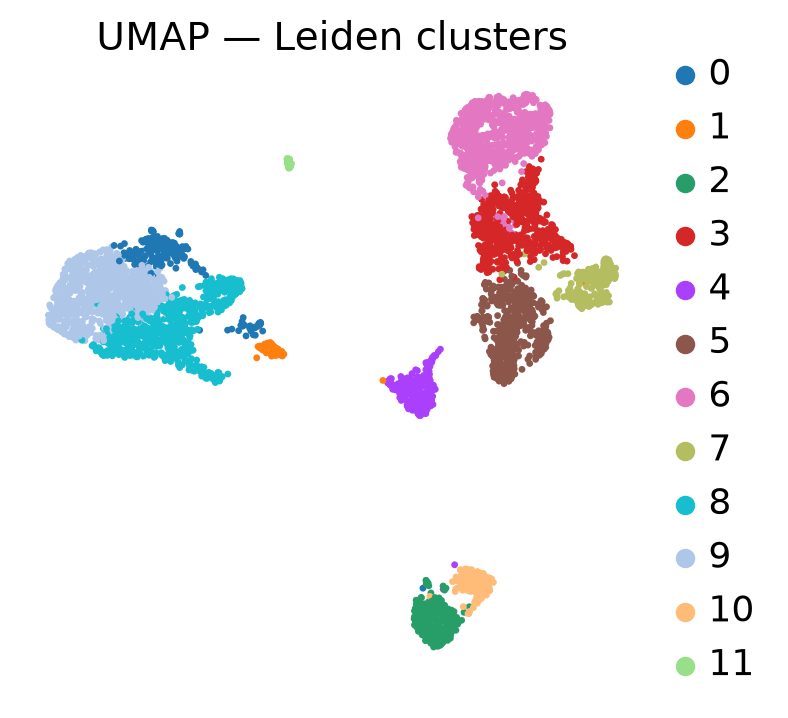

In [3]:
rsc.pp.neighbors(adata, use_rep="X_spectral", n_neighbors=30)
rsc.tl.umap(adata, min_dist=0.3)
rsc.tl.leiden(adata, resolution=0.5)

sc.pl.umap(adata, color="leiden",
           title="UMAP — Leiden clusters")

## 3. Annotate cell types from gene activity

A gene activity matrix counts the Tn5 insertions over each gene body and its
promoter (`ga.pp.make_gene_matrix`). After normalisation, every cell gets a
score for each lineage from a few canonical marker genes, and each cluster
takes the lineage it scores highest for, provided that lineage stands out
(z-score above 0.75 across clusters). Clusters with no clear lineage are labelled
`Other`.

13:56:30 - gatac.pp.gene - INFO - Loading gene annotation from data/gencode.v44.primary_assembly.annotation.gtf.gz


13:56:33 - gatac.pp.gene - INFO - Loaded 244,742 transcript regulatory domains (for gene-level output)


13:56:33 - gatac.pp.gene - INFO - Processing pbmc_fragments.parquet


13:57:30 - gatac.pp.gene - INFO - Using uint16 dtype (max count: 1233)


... storing 'chrom' as categorical


...

... storing 'strand' as categorical


... storing 'gene_name' as categorical


... storing 'index' as categorical


13:57:30 - gatac.pp.gene - INFO - Created pbmc_fragments_gene_matrix.h5ad: 5,543 cells × 62,754 genes (57.1s)


Gene activity matrix in 60.3s


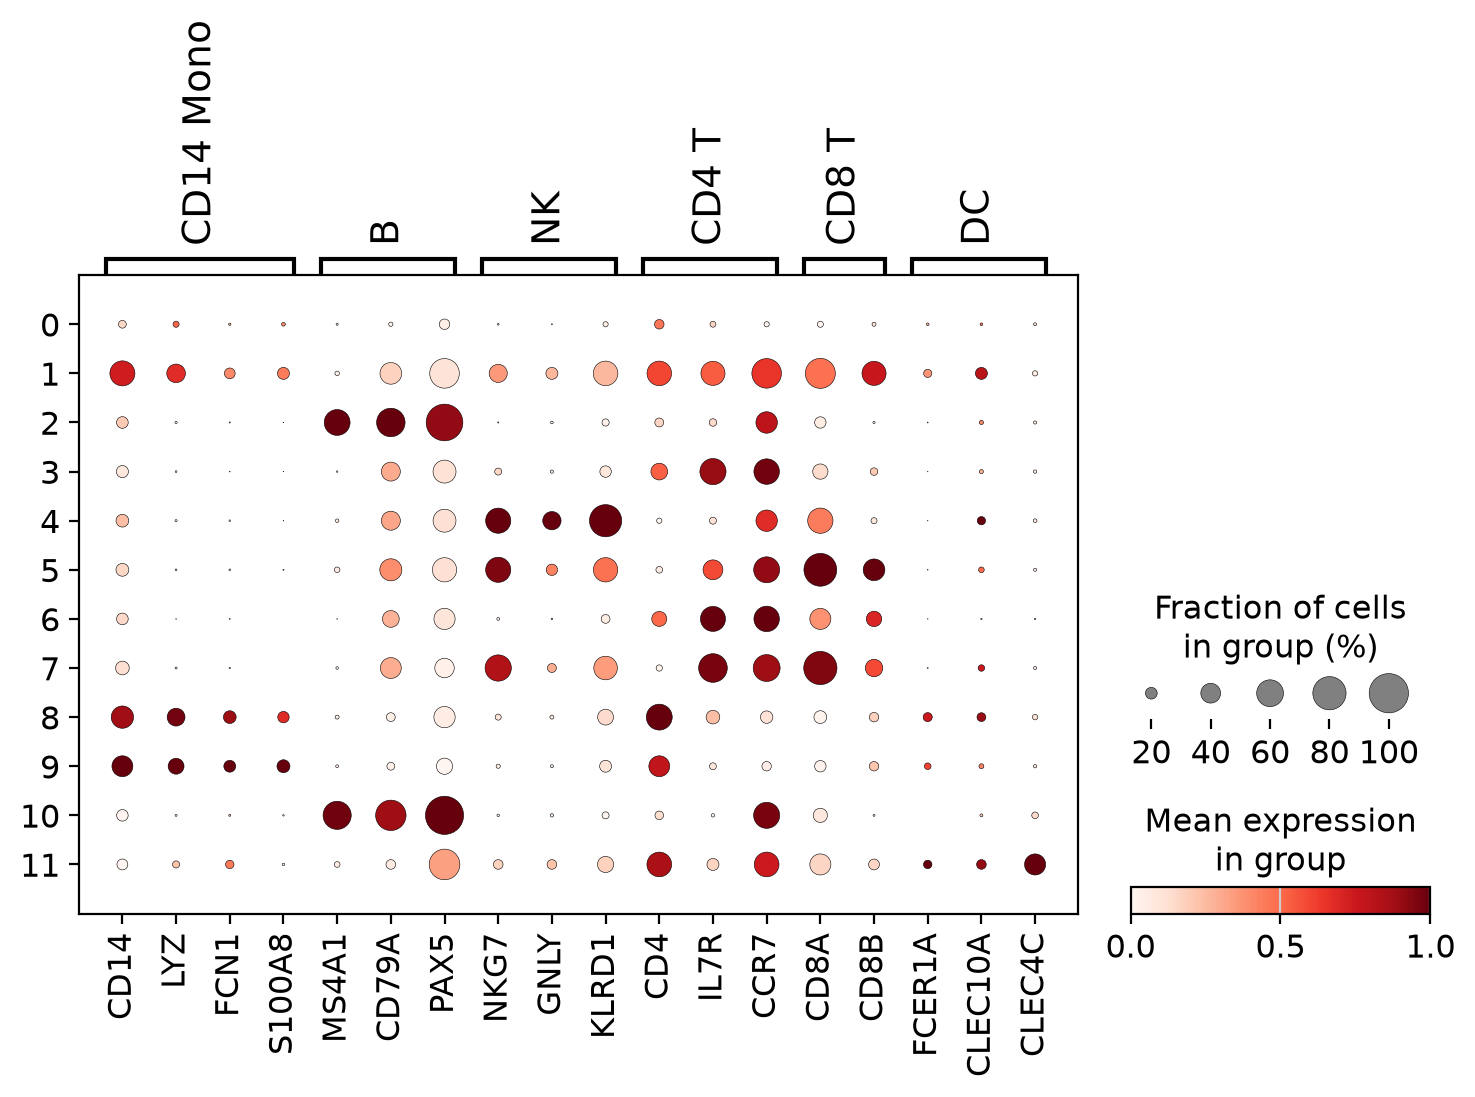

In [4]:
import pandas as pd

MARKERS = {
    "CD14 Mono": ["CD14", "LYZ", "FCN1", "S100A8"],
    "B": ["MS4A1", "CD79A", "PAX5"],
    "NK": ["NKG7", "GNLY", "KLRD1"],
    "CD4 T": ["CD4", "IL7R", "CCR7"],
    "CD8 T": ["CD8A", "CD8B"],
    "DC": ["FCER1A", "CLEC10A", "CLEC4C"],
}

# Every cell kept by the QC of notebook 01 has at least 1,500 unique fragments
t0 = time.perf_counter()
gene_adata = ga.pp.make_gene_matrix(
    "data/pbmc_fragments.parquet",
    "data/gencode.v44.primary_assembly.annotation.gtf.gz",
    min_fragments_per_cell=1000,
)[adata.obs_names].copy()
print(f"Gene activity matrix in {time.perf_counter() - t0:.1f}s")

sc.pp.normalize_total(gene_adata, target_sum=1e4)
sc.pp.log1p(gene_adata)
gene_adata.obs["leiden"] = adata.obs["leiden"].values
sc.pl.dotplot(gene_adata, MARKERS, groupby="leiden", standard_scale="var")

In [5]:
for name, genes in MARKERS.items():
    sc.tl.score_genes(gene_adata, genes, score_name=name, random_state=0)
scores = gene_adata.obs.groupby("leiden", observed=True)[list(MARKERS)].mean()
z = (scores - scores.mean()) / scores.std()
labels = z.idxmax(axis=1).where(z.max(axis=1) > 0.75, "Other")

adata.obs["cell_type"] = pd.Categorical(adata.obs["leiden"].map(labels))
z.round(2).assign(cell_type=labels)

,CD14 Mono,B,NK,CD4 T,CD8 T,DC,cell_type
leiden,,,,,,,
0,0.58,-0.37,-0.53,-0.62,-0.49,-0.12,Other
1,0.71,-0.54,-0.01,0.01,0.58,-0.15,Other
2,-0.49,2.12,-0.63,-0.47,-0.82,-0.42,B
3,-0.65,-0.36,-0.42,1.65,-0.50,-0.61,CD4 T
4,-0.57,-0.32,2.51,-1.14,0.10,0.03,NK
5,-0.60,-0.27,1.21,0.25,2.11,-0.44,CD8 T
6,-0.53,-0.36,-0.57,1.88,0.47,-0.94,CD4 T
7,-0.66,-0.55,0.77,0.73,1.59,-0.25,CD8 T
8,1.54,-0.64,-0.62,-0.66,-0.85,0.49,CD14 Mono


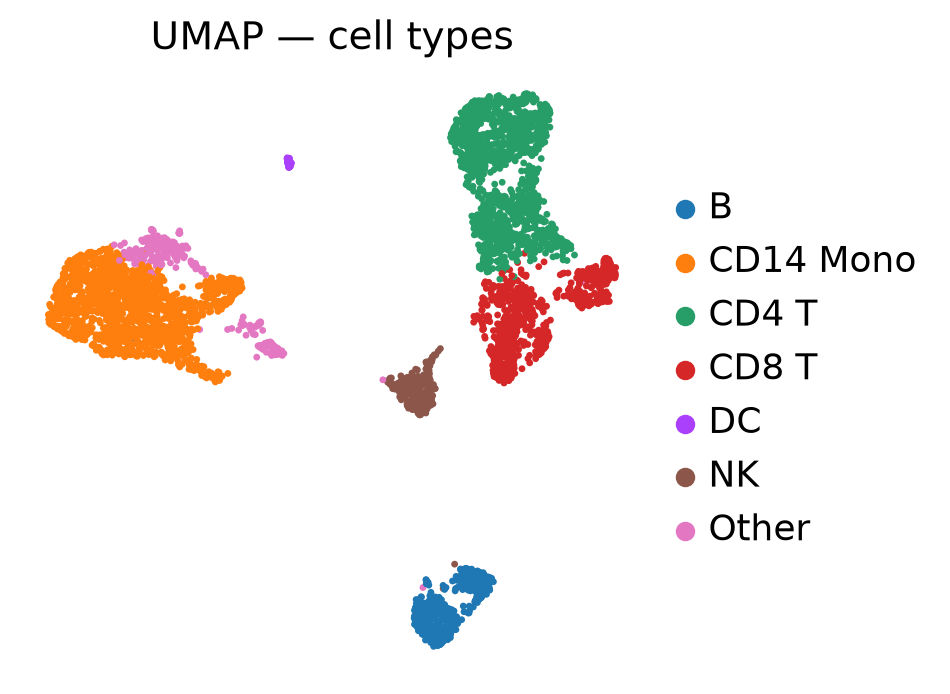

In [6]:
sc.pl.umap(adata, color="cell_type", title="UMAP — cell types")

## 4. Call peaks per cluster

We are running for each Leiden cluster a gpu accelerated implementation of MACS3 (gmacs).

In [7]:
t0 = time.perf_counter()
ga.peak.call(
    adata,
    groupby="leiden",
    parquet_path="data/pbmc_fragments.parquet",
    genome="hg38",
)
print(f"Peak calling in {time.perf_counter() - t0:.1f}s")

13:57:35 - gatac.peak.peaks - INFO - Using genome length: 3,088,269,832 bp


13:57:35 - gatac.peak.peaks - INFO - Calling peaks for 12 groups in 'leiden'


Groups:   0%|          | 0/12 [00:00<?, ?it/s]

13:57:35 - gatac.peak.peaks - INFO - Processing group: 7


13:57:36 - gatac.peak.peaks - INFO -   4,969,070 fragments, calling peaks...


...

14:03:06 - gatac.peak.peaks - INFO -   Found 56,955 peaks


14:03:06 - gatac.peak.peaks - INFO - Processing group: 1


14:03:07 - gatac.peak.peaks - INFO -   2,540,504 fragments, calling peaks...


14:03:35 - gatac.peak.peaks - INFO -   Found 65,560 peaks


Peak calling in 360.9s


In [8]:
# Number of peaks per cluster
for group, peak_df in adata.uns["gmacs"].items():
    print(f"  Cluster {group}: {len(peak_df):,} peaks")


  Cluster 7: 45,013 peaks
  Cluster 5: 56,241 peaks
  Cluster 9: 92,078 peaks
  Cluster 6: 53,215 peaks
  Cluster 3: 53,670 peaks
  Cluster 10: 54,220 peaks
  Cluster 2: 60,008 peaks
  Cluster 8: 103,944 peaks
  Cluster 11: 58,217 peaks
  Cluster 0: 58,660 peaks
  Cluster 4: 56,955 peaks
  Cluster 1: 65,560 peaks


## 5. Merge peaks across clusters

In [9]:
ga.peak.merge(adata,chrom_sizes="hg38")
adata.uns["peaks"]

,chrom,start,end,name,score,strand,signal_value,p_value,q_value,peak
193335,chr1,778379,778880,.,1000,.,18.072289,1000.000000,1000.000000,250
45019,chr1,827219,827720,.,1000,.,22.124493,1000.000000,1000.000000,250
193339,chr1,869631,870132,.,1000,.,32.093023,1000.000000,1000.000000,250
101267,chr1,958996,959497,.,1000,.,17.798254,1000.000000,1000.000000,250
414476,chr1,1013118,1013619,.,1000,.,17.950000,1000.000000,1000.000000,250
...,...,...,...,...,...,...,...,...,...,...
595764,chr15,92998428,92998929,.,13,.,2.985075,3.371741,1.315264,250
604601,chr2,2968589,2969090,.,13,.,2.985075,3.371741,1.315264,250
609788,chr20,24672835,24673336,.,13,.,2.985075,3.371741,1.315264,250
617443,chr4,79678189,79678690,.,13,.,2.985075,3.371741,1.315264,250


## 6. Build cell × peak matrix

In [10]:
t0 = time.perf_counter()
peak_adata = ga.peak.make_matrix(
    adata,parquet_path="data/pbmc_fragments.parquet",
)
print(f"Peak matrix built in {time.perf_counter() - t0:.1f}s")
print(peak_adata)

14:03:36 - gatac.peak.peaks - INFO - Counting fragments in 194,467 peaks


14:03:36 - gatac.peak.peaks - INFO - Processing single parquet file


Parquet files:   0%|          | 0/1 [00:00<?, ?it/s]

14:03:40 - gatac.pp.gene - INFO - Using uint8 dtype (max count: 70)


14:03:40 - gatac.peak.peaks - INFO - Peak matrix: 5,001 cells × 194,467 peaks


14:03:40 - gatac.peak.peaks - INFO - Sparsity: 95.56%


Peak matrix built in 4.4s
AnnData object with n_obs × n_vars = 5001 × 194467
    obs: 'barcode', 'n_unique', 'tsse_score', 'duplicate_fraction', 'mito_fraction', 'leiden', 'cell_type'
    layers: None (.X)


## 7. Save

In [11]:
# Keep the UMAP with the peak matrix, for plotting in the next notebooks
peak_adata.obsm["X_umap"] = adata[peak_adata.obs_names].obsm["X_umap"]
peak_adata.write_h5ad("data/pbmc_peaks.h5ad")
print("Saved → data/pbmc_peaks.h5ad")

Saved → data/pbmc_peaks.h5ad


## Next steps

- [03 – Motif enrichment](03_motif_enrichment.ipynb)
- [04 – chromVAR](04_chromvar.ipynb)
- [06 – TF footprinting](06_footprinting.ipynb)